In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

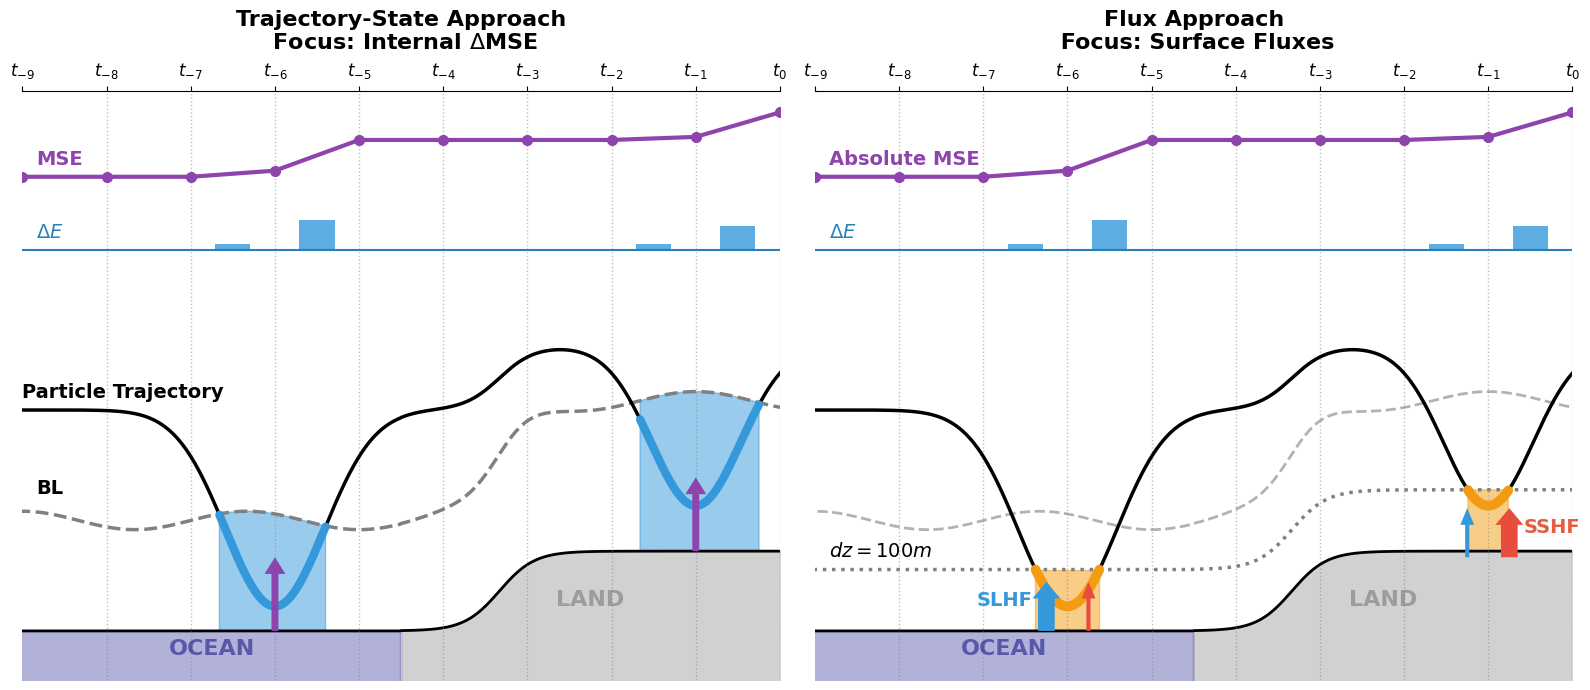

In [158]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), layout='tight')
fig.patch.set_facecolor('white')

x = np.linspace(-60, 10, 1000)
times = np.arange(-54, 1, 6)

ocean_mask = x < -27
land_mask = x >= -27

terrain = np.where(ocean_mask, 0, 1.3 / (1 + np.exp(-0.8 * (x + 20))))

blh = 1.8 + terrain * 1.5 + 0.15 * np.sin((x + 10) * np.pi / 8)

dz = terrain + 1

traj_base = 3.6 + terrain * 0.8
dip_ocean = 3.2 * np.exp(-((x + 36) / 5)**2)
dip_land = 2.6 * np.exp(-((x + 6) / 4.5)**2)
traj = traj_base - dip_ocean - dip_land

mse_x = times
mse_y = np.array([7.4, 7.4, 7.4, 7.5, 8.0, 8.0, 8.0, 8.0, 8.05, 8.45])

for ax in axes:
    ax.fill_between(x, -1.0, terrain, where=ocean_mask, color='navy', alpha=0.3)
    ax.fill_between(x, -1.0, terrain, where=land_mask, color='dimgrey', alpha=0.3)
    ax.plot(x, terrain, color='black', lw=2)
    
    ax.text(-40.5, -0.4, 'OCEAN', color='navy', fontsize=16, fontweight='bold', ha='center', alpha=0.5)
    ax.text(-13.5, 0.4, 'LAND', color='dimgrey', fontsize=16, fontweight='bold', ha='center', alpha=0.5)
    
    for t in np.arange(-48, 1, 6):
        ax.axvline(t, color='gray', ls=':', lw=1, alpha=0.5)
        
    ax.set_xlim(-54, 0)
    ax.set_ylim(-0.8, 8.8)
    ax.xaxis.tick_top()
    ax.set_xticks(times)
    ax.set_xticklabels([r'$t_{-9}$', r'$t_{-8}$', r'$t_{-7}$', r'$t_{-6}$', r'$t_{-5}$', r'$t_{-4}$', r'$t_{-3}$', r'$t_{-2}$', r'$t_{-1}$', r'$t_{0}$',], fontsize=12)
#    ax.set_xticklabels([rf't_{np.round(t/6, 0)}' for t in times], fontsize=13)
    ax.set_yticks([])
    for spine in ['right', 'left', 'bottom']:
        ax.spines[spine].set_visible(False)
        
        
# PANEL 1
        
ax1 = axes[0]
ax1.set_title('Trajectory-State Approach\n Focus: Internal $\Delta$MSE', fontsize=16, fontweight='bold', pad=30)

ax1.plot(x, blh, color='grey', ls='--', lw=2.5)
idx_53 = np.argmin(np.abs(x - (-53)))
ax1.text(-53, blh[idx_53] + 0.3, 'BL', color='black', fontweight='bold', fontsize=14)

ax1.plot(x, traj, color='black', lw=2.5)

ax1.plot(mse_x, mse_y, color='#8e44ad', marker='o', lw=3, markersize=7)
ax1.text(-53, mse_line[0] + 0.2, 'MSE', color='#8e44ad', fontsize=14, fontweight='bold')

base_y = 6.2
ax1.axhline(base_y, color='#2980b9', lw=1.5)
ax1.text(-53, base_y + 0.2, r'$\Delta E$', color='#2980b9', fontsize=14, fontweight='bold')
bars_x = [-45, -39, -33, -27, -21, -15, -9, -3]
bars_y = [0.0, 0.1, 0.5, 0.00, -0.00, -0.00, 0.1, 0.4]
for bx, by in zip(bars_x, bars_y):
    color='#3498db' if by > 0 else '#e74c3c'
    ax1.bar(bx, by, width=2.5, bottom=base_y, color=color, alpha=0.8)
    
mask_state_uptake = (traj < blh) & ( ((x > -40) & (x < -28)) | ((x > -10) & (x < 0)) )

traj_state_highlight = traj.copy()
traj_state_highlight[~mask_state_uptake] = np.nan
ax1.plot(x, traj_state_highlight, color='#3498db', lw=6, solid_capstyle='round')

ax1.annotate('', xy=(-36, 1.2), xytext=(-36, 0.0), 
             arrowprops=dict(facecolor='#8e44ad', edgecolor='none', width=5, headwidth=15))
ax1.annotate('', xy=(-6, 2.5), xytext=(-6, 1.3), 
             arrowprops=dict(facecolor='#8e44ad', edgecolor='none', width=5, headwidth=15))

ax1.fill_between(x, terrain, blh, where=mask_state_uptake, color='#3498db', alpha=0.5)

ax1.text(-54, 3.8, 'Particle Trajectory', color='black', fontsize=14, fontweight='bold')

# PANEL 2

ax2 = axes = axes[1]
ax2.set_title('Flux Approach\n Focus: Surface Fluxes', fontsize=16, fontweight='bold', pad=30)

ax2.plot(x, blh, color='grey', ls='--', lw=2, alpha=0.6)
ax2.plot(x, dz, color='grey', ls=':', lw=2.5)
ax2.text(-53, dz[idx_53] + 0.2, r'$dz=100m$', color='black', fontweight='bold', fontsize=14)

ax2.plot(x, traj, color='black', lw=2.5)

ax2.plot(mse_x, mse_y, color='#8e44ad', lw=3, marker='o', markersize=7)
ax2.text(-53, mse_y[0] + 0.2, 'Absolute MSE', color='#8e44ad', fontsize=14, fontweight='bold')

ax2.axhline(base_y, color='#2980b9', lw=1.5)
ax2.text(-53, base_y + 0.2, r'$\Delta E$', color='#2980b9', fontsize=14, fontweight='bold')
for bx, by in zip(bars_x, bars_y):
    color='#3498db' if by > 0 else '#e74c3c'
    ax2.bar(bx, by, width=2.5, bottom=base_y, color=color, alpha=0.8)
    
mask_flux_uptake = (traj <= dz)

traj_flux_highlight = traj.copy()
traj_flux_highlight[~mask_flux_uptake] = np.nan 
ax2.plot(x, traj_flux_highlight, color='#f39c12', lw=7, solid_capstyle='round')

ax2.annotate('', xy=(-37.5, 0.8), xytext=(-37.5, 0), arrowprops=dict(facecolor='#3498db', edgecolor='none', width=12, headwidth=20))
ax2.annotate('', xy=(-34.5, 0.8), xytext=(-34.5, 0), arrowprops=dict(facecolor='#e74c3c', edgecolor='none', width=3, headwidth=10))
ax2.text(-38.5, 0.4, 'SLHF', color='#3498db', fontsize=14, ha='right', fontweight='bold')

ax2.annotate('', xy=(-7.5, 2.0), xytext=(-7.5, 1.2), arrowprops=dict(facecolor='#3498db', edgecolor='none', width=3, headwidth=10))
ax2.annotate('', xy=(-4.5, 2.0), xytext=(-4.5, 1.2), arrowprops=dict(facecolor='#e74c3c', edgecolor='none', width=12, headwidth=20))
ax2.text(-3.5, 1.6, 'SSHF', color='#e75c3c', fontsize=14, ha='left', fontweight='bold')

ax2.fill_between(x, terrain, dz, where=mask_flux_uptake, color='#f39c12', alpha=0.5)

fig.savefig('graphic.pdf')

In [20]:
times

(-48, 1, 6)